In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/Data.csv")

print(df.shape)
print(df.dtypes)

(377719, 7)
time                        object
Cyclone_Inlet_Gas_Temp      object
Cyclone_Material_Temp       object
Cyclone_Outlet_Gas_draft    object
Cyclone_cone_draft          object
Cyclone_Gas_Outlet_Temp     object
Cyclone_Inlet_Draft         object
dtype: object


In [2]:
import pandas as pd

master_df = pd.read_csv("../data/Data.csv")
df = master_df.copy()

print("Raw dataset shape:", master_df.shape)

Raw dataset shape: (377719, 7)


In [3]:
print("Shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nData types:")
display(df.dtypes)

Shape: (377719, 7)

Column names:
['time', 'Cyclone_Inlet_Gas_Temp', 'Cyclone_Material_Temp', 'Cyclone_Outlet_Gas_draft', 'Cyclone_cone_draft', 'Cyclone_Gas_Outlet_Temp', 'Cyclone_Inlet_Draft']

First 5 rows:


,time,Cyclone_Inlet_Gas_Temp,Cyclone_Material_Temp,Cyclone_Outlet_Gas_draft,Cyclone_cone_draft,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Draft
0,01-01-2017 00:00,867.63,910.42,-189.54,-186.04,852.13,-145.9
1,01-01-2017 00:05,879.23,918.14,-184.33,-182.1,862.53,-149.76
2,01-01-2017 00:10,875.67,924.18,-181.26,-166.47,866.06,-145.01
3,01-01-2017 00:15,875.28,923.15,-179.15,-174.83,865.85,-142.82
4,01-01-2017 00:20,891.66,934.26,-178.32,-173.72,876.06,-143.39



Last 5 rows:


,time,Cyclone_Inlet_Gas_Temp,Cyclone_Material_Temp,Cyclone_Outlet_Gas_draft,Cyclone_cone_draft,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Draft
377714,08-07-2020 11:55,899.42,919.79,-224.07,-209.77,901.01,-175.15
377715,08-07-2020 12:00,879.9,895.02,-228.04,-211.28,878.08,-176.94
377716,08-07-2020 12:05,887.2,895.7,-230.11,-214.65,885.32,-179.18
377717,08-07-2020 12:10,908.5,916.33,-231.51,-218.09,906.2,-181.96
377718,08-07-2020 12:15,880.86,905.31,-235.02,-219.44,882.1,-184.02



Data types:


time                        object
Cyclone_Inlet_Gas_Temp      object
Cyclone_Material_Temp       object
Cyclone_Outlet_Gas_draft    object
Cyclone_cone_draft          object
Cyclone_Gas_Outlet_Temp     object
Cyclone_Inlet_Draft         object
dtype: object

In [4]:
# Check missing values
print("Missing values:")
display(df.isna().sum())

# Check unique data types/values in each sensor column
sensor_cols = df.columns[1:]

for col in sensor_cols:
    print(f"\n--- {col} ---")
    print("Unique values:", df[col].nunique())
    print("Sample values:")
    print(df[col].dropna().unique()[:20])

Missing values:


time                        0
Cyclone_Inlet_Gas_Temp      0
Cyclone_Material_Temp       0
Cyclone_Outlet_Gas_draft    0
Cyclone_cone_draft          0
Cyclone_Gas_Outlet_Temp     0
Cyclone_Inlet_Draft         0
dtype: int64


--- Cyclone_Inlet_Gas_Temp ---
Unique values: 39736
Sample values:
['867.63' '879.23' '875.67' '875.28' '891.66' '878.54' '905.94' '877.83'
 '871.01' '905.46' '875.11' '901.2' '874.51' '882.43' '870.1' '898.47'
 '860.7' '890.84' '862.19' '871.39']

--- Cyclone_Material_Temp ---
Unique values: 39662
Sample values:
['910.42' '918.14' '924.18' '923.15' '934.26' '932.38' '951.32' '939.63'
 '938.73' '939.06' '942.88' '943.19' '927.81' '938.17' '925.33' '944.3'
 '921.5' '931.01' '922.43' '919.13']

--- Cyclone_Outlet_Gas_draft ---
Unique values: 27669
Sample values:
['-189.54' '-184.33' '-181.26' '-179.15' '-178.32' '-188.37' '-184.2'
 '-182.63' '-176.8' '-182.62' '-178.25' '-182.74' '-180.99' '-175.01'
 '-182.94' '-179.05' '-179.11' '-178.89' '-180.98' '-175.39']

--- Cyclone_cone_draft ---
Unique values: 26487
Sample values:
['-186.04' '-182.1' '-166.47' '-174.83' '-173.72' '-177.98' '-182.67'
 '-181.17' '-178.23' '-168.39' '-172.76' '-179.49' '-167.2' '-176.9'
 '-165.5' '-164.8' '-180.89

In [5]:
for col in sensor_cols:
    numeric_values = pd.to_numeric(df[col], errors="coerce")
    
    print(f"\n{col}")
    print("Total records:", len(df))
    print("Numeric:", numeric_values.notna().sum())
    print("Non-numeric:", numeric_values.isna().sum())
    
    if numeric_values.isna().sum() > 0:
        print("Non-numeric values:")
        print(df.loc[numeric_values.isna(), col].value_counts())


Cyclone_Inlet_Gas_Temp
Total records: 377719
Numeric: 376399
Non-numeric: 1320
Non-numeric values:
Cyclone_Inlet_Gas_Temp
Not Connect     723
I/O Timeout     470
Configure       108
Scan Timeout     17
Comm Fail         2
Name: count, dtype: int64

Cyclone_Material_Temp
Total records: 377719
Numeric: 376128
Non-numeric: 1591
Non-numeric values:
Cyclone_Material_Temp
Not Connect     723
I/O Timeout     470
Unit Down       271
Configure       108
Scan Timeout     17
Comm Fail         2
Name: count, dtype: int64

Cyclone_Outlet_Gas_draft
Total records: 377719
Numeric: 376398
Non-numeric: 1321
Non-numeric values:
Cyclone_Outlet_Gas_draft
Not Connect     723
I/O Timeout     470
Configure       108
Scan Timeout     17
Comm Fail         2
Unit Down         1
Name: count, dtype: int64

Cyclone_cone_draft
Total records: 377719
Numeric: 376399
Non-numeric: 1320
Non-numeric values:
Cyclone_cone_draft
Not Connect     723
I/O Timeout     470
Configure       108
Scan Timeout     17
Comm Fail       

In [6]:
print("Sample timestamps:")
display(df["time"].head(10))

print("\nTimestamp string lengths:")
print(df["time"].astype(str).str.len().value_counts())

print("\nUnique timestamp formats/examples:")
display(df["time"].astype(str).drop_duplicates().head(20))

Sample timestamps:


0    01-01-2017 00:00
1    01-01-2017 00:05
2    01-01-2017 00:10
3    01-01-2017 00:15
4    01-01-2017 00:20
5    01-01-2017 00:25
6    01-01-2017 00:30
7    01-01-2017 00:35
8    01-01-2017 00:40
9    01-01-2017 00:45
Name: time, dtype: object


Timestamp string lengths:
time
16    178204
15    124635
14     74880
Name: count, dtype: int64

Unique timestamp formats/examples:


0     01-01-2017 00:00
1     01-01-2017 00:05
2     01-01-2017 00:10
3     01-01-2017 00:15
4     01-01-2017 00:20
5     01-01-2017 00:25
6     01-01-2017 00:30
7     01-01-2017 00:35
8     01-01-2017 00:40
9     01-01-2017 00:45
10    01-01-2017 00:50
11    01-01-2017 00:55
12    01-01-2017 01:00
13    01-01-2017 01:05
14    01-01-2017 01:10
15    01-01-2017 01:15
16    01-01-2017 01:20
17    01-01-2017 01:25
18    01-01-2017 01:30
19    01-01-2017 01:35
Name: time, dtype: object

In [7]:
# Find timestamps that don't have the standard 16-character format
timestamp_lengths = df["time"].astype(str).str.len()

for length in sorted(timestamp_lengths.unique()):
    print(f"\n--- Length {length} ---")
    display(
        df.loc[timestamp_lengths == length, "time"]
        .drop_duplicates()
        .head(20)
    )


--- Length 14 ---


3456    1/13/2017 0:00
3457    1/13/2017 0:05
3458    1/13/2017 0:10
3459    1/13/2017 0:15
3460    1/13/2017 0:20
3461    1/13/2017 0:25
3462    1/13/2017 0:30
3463    1/13/2017 0:35
3464    1/13/2017 0:40
3465    1/13/2017 0:45
3466    1/13/2017 0:50
3467    1/13/2017 0:55
3468    1/13/2017 1:00
3469    1/13/2017 1:05
3470    1/13/2017 1:10
3471    1/13/2017 1:15
3472    1/13/2017 1:20
3473    1/13/2017 1:25
3474    1/13/2017 1:30
3475    1/13/2017 1:35
Name: time, dtype: object


--- Length 15 ---


3576    1/13/2017 10:00
3577    1/13/2017 10:05
3578    1/13/2017 10:10
3579    1/13/2017 10:15
3580    1/13/2017 10:20
3581    1/13/2017 10:25
3582    1/13/2017 10:30
3583    1/13/2017 10:35
3584    1/13/2017 10:40
3585    1/13/2017 10:45
3586    1/13/2017 10:50
3587    1/13/2017 10:55
3588    1/13/2017 11:00
3589    1/13/2017 11:05
3590    1/13/2017 11:10
3591    1/13/2017 11:15
3592    1/13/2017 11:20
3593    1/13/2017 11:25
3594    1/13/2017 11:30
3595    1/13/2017 11:35
Name: time, dtype: object


--- Length 16 ---


0     01-01-2017 00:00
1     01-01-2017 00:05
2     01-01-2017 00:10
3     01-01-2017 00:15
4     01-01-2017 00:20
5     01-01-2017 00:25
6     01-01-2017 00:30
7     01-01-2017 00:35
8     01-01-2017 00:40
9     01-01-2017 00:45
10    01-01-2017 00:50
11    01-01-2017 00:55
12    01-01-2017 01:00
13    01-01-2017 01:05
14    01-01-2017 01:10
15    01-01-2017 01:15
16    01-01-2017 01:20
17    01-01-2017 01:25
18    01-01-2017 01:30
19    01-01-2017 01:35
Name: time, dtype: object

In [8]:
# Identify the two timestamp styles
slash_mask = df["time"].astype(str).str.contains("/", regex=False)
dash_mask = df["time"].astype(str).str.contains("-", regex=False)

print("Rows using '/' format:", slash_mask.sum())
print("Rows using '-' format:", dash_mask.sum())

print("\nFirst row using '/' format:")
print(df.loc[slash_mask, "time"].head(1).to_string(index=False))

print("\nLast row using '-' format:")
print(df.loc[dash_mask, "time"].tail(1).to_string(index=False))

Rows using '/' format: 227235
Rows using '-' format: 150484

First row using '/' format:
1/13/2017 0:00

Last row using '-' format:
08-07-2020 12:15


In [9]:
# Identify timestamp format for each row
df["date_format"] = np.where(
    df["time"].astype(str).str.contains("/", regex=False),
    "slash",
    "dash"
)

# Find rows where the timestamp format changes from the previous row
format_changes = df["date_format"].ne(df["date_format"].shift())

print("Number of format segments:", format_changes.sum())

print("\nFormat transition points:")
display(
    df.loc[format_changes, ["time", "date_format"]]
)

Number of format segments: 87

Format transition points:


,time,date_format
0,01-01-2017 00:00,dash
3456,1/13/2017 0:00,slash
8928,02-01-2017 00:00,dash
12384,2/13/2017 0:00,slash
16992,03-01-2017 00:00,dash
...,...,...
358275,06-01-2020 00:00,dash
361731,6/13/2020 0:00,slash
366915,07-01-2020 00:00,dash
370371,7/13/2020 0:00,slash


In [10]:
# Identify timestamp format
slash_mask = df["time"].astype(str).str.contains("/", regex=False)

# Create a new datetime column
df["time_dt"] = pd.NaT

# DD-MM-YYYY HH:MM
df.loc[~slash_mask, "time_dt"] = pd.to_datetime(
    df.loc[~slash_mask, "time"],
    format="%d-%m-%Y %H:%M"
)

# M/D/YYYY H:MM
df.loc[slash_mask, "time_dt"] = pd.to_datetime(
    df.loc[slash_mask, "time"],
    format="%m/%d/%Y %H:%M"
)

print("Unparsed timestamps:", df["time_dt"].isna().sum())
print("Start:", df["time_dt"].min())
print("End:", df["time_dt"].max())

Unparsed timestamps: 0
Start: 2017-01-01 00:00:00
End: 2020-12-07 23:55:00


In [11]:
print("Chronologically sorted:", df["time_dt"].is_monotonic_increasing)

Chronologically sorted: False


In [12]:
# Inspect timestamps around month transitions
for start, end in [(3400, 3500), (8800, 9000), (12350, 12420)]:
    print(f"\n--- Rows {start} to {end} ---")
    display(df.loc[start:end, ["time"]].head(10))
    display(df.loc[start:end, ["time"]].tail(10))


--- Rows 3400 to 3500 ---


,time
3400,01-12-2017 19:20
3401,01-12-2017 19:25
3402,01-12-2017 19:30
3403,01-12-2017 19:35
3404,01-12-2017 19:40
3405,01-12-2017 19:45
3406,01-12-2017 19:50
3407,01-12-2017 19:55
3408,01-12-2017 20:00
3409,01-12-2017 20:05


,time
3491,1/13/2017 2:55
3492,1/13/2017 3:00
3493,1/13/2017 3:05
3494,1/13/2017 3:10
3495,1/13/2017 3:15
3496,1/13/2017 3:20
3497,1/13/2017 3:25
3498,1/13/2017 3:30
3499,1/13/2017 3:35
3500,1/13/2017 3:40



--- Rows 8800 to 9000 ---


,time
8800,1/31/2017 13:20
8801,1/31/2017 13:25
8802,1/31/2017 13:30
8803,1/31/2017 13:35
8804,1/31/2017 13:40
8805,1/31/2017 13:45
8806,1/31/2017 13:50
8807,1/31/2017 13:55
8808,1/31/2017 14:00
8809,1/31/2017 14:05


,time
8991,02-01-2017 05:15
8992,02-01-2017 05:20
8993,02-01-2017 05:25
8994,02-01-2017 05:30
8995,02-01-2017 05:35
8996,02-01-2017 05:40
8997,02-01-2017 05:45
8998,02-01-2017 05:50
8999,02-01-2017 05:55
9000,02-01-2017 06:00



--- Rows 12350 to 12420 ---


,time
12350,02-12-2017 21:10
12351,02-12-2017 21:15
12352,02-12-2017 21:20
12353,02-12-2017 21:25
12354,02-12-2017 21:30
12355,02-12-2017 21:35
12356,02-12-2017 21:40
12357,02-12-2017 21:45
12358,02-12-2017 21:50
12359,02-12-2017 21:55


,time
12411,2/13/2017 2:15
12412,2/13/2017 2:20
12413,2/13/2017 2:25
12414,2/13/2017 2:30
12415,2/13/2017 2:35
12416,2/13/2017 2:40
12417,2/13/2017 2:45
12418,2/13/2017 2:50
12419,2/13/2017 2:55
12420,2/13/2017 3:00


In [13]:
print("Around first transition:")
display(df.loc[3448:3465, ["time"]])

print("\nAround second transition:")
display(df.loc[8918:8935, ["time"]])

print("\nAround last rows:")
display(df.tail(10)[["time"]])

Around first transition:


,time
3448,01-12-2017 23:20
3449,01-12-2017 23:25
3450,01-12-2017 23:30
3451,01-12-2017 23:35
3452,01-12-2017 23:40
3453,01-12-2017 23:45
3454,01-12-2017 23:50
3455,01-12-2017 23:55
3456,1/13/2017 0:00
3457,1/13/2017 0:05



Around second transition:


,time
8918,1/31/2017 23:10
8919,1/31/2017 23:15
8920,1/31/2017 23:20
8921,1/31/2017 23:25
8922,1/31/2017 23:30
8923,1/31/2017 23:35
8924,1/31/2017 23:40
8925,1/31/2017 23:45
8926,1/31/2017 23:50
8927,1/31/2017 23:55



Around last rows:


,time
377709,08-07-2020 11:30
377710,08-07-2020 11:35
377711,08-07-2020 11:40
377712,08-07-2020 11:45
377713,08-07-2020 11:50
377714,08-07-2020 11:55
377715,08-07-2020 12:00
377716,08-07-2020 12:05
377717,08-07-2020 12:10
377718,08-07-2020 12:15


In [14]:
df.drop(columns=["time_dt"], inplace=True)

In [15]:
slash_mask = df["time"].astype(str).str.contains("/", regex=False)

df["time_dt"] = pd.NaT

# Dash format: DD-MM-YYYY HH:MM
df.loc[~slash_mask, "time_dt"] = pd.to_datetime(
    df.loc[~slash_mask, "time"],
    format="%d-%m-%Y %H:%M"
)

# Slash format: M/D/YYYY H:MM
df.loc[slash_mask, "time_dt"] = pd.to_datetime(
    df.loc[slash_mask, "time"],
    format="%m/%d/%Y %H:%M"
)

In [16]:
print("Unparsed:", df["time_dt"].isna().sum())
print("First:", df["time_dt"].iloc[0])
print("Transition:", df["time_dt"].iloc[3456])
print("Next transition:", df["time_dt"].iloc[8928])
print("Last:", df["time_dt"].iloc[-1])
print("Maximum:", df["time_dt"].max())

Unparsed: 0
First: 2017-01-01 00:00:00
Transition: 2017-01-13 00:00:00
Next transition: 2017-01-02 00:00:00
Last: 2020-07-08 12:15:00
Maximum: 2020-12-07 23:55:00


In [17]:
slash_mask = df["time"].astype(str).str.contains("/", regex=False)

df["time_dt"] = pd.NaT

# Dash format: MM-DD-YYYY
df.loc[~slash_mask, "time_dt"] = pd.to_datetime(
    df.loc[~slash_mask, "time"],
    format="%m-%d-%Y %H:%M",
    errors="coerce"
)

# Slash format: M/D/YYYY
df.loc[slash_mask, "time_dt"] = pd.to_datetime(
    df.loc[slash_mask, "time"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)


In [18]:
print("Unparsed timestamps:", df["time_dt"].isna().sum())

Unparsed timestamps: 0


In [19]:
time_diff = df["time_dt"].diff()

print(time_diff.value_counts().head(10))

time_dt
0 days 00:05:00    377715
1 days 00:00:00         3
Name: count, dtype: int64


In [20]:
print("Total rows:", len(df))
print("5-minute intervals:", (time_diff == pd.Timedelta(minutes=5)).sum())
print("Other intervals:", (time_diff != pd.Timedelta(minutes=5)).sum())

Total rows: 377719
5-minute intervals: 377715
Other intervals: 4


In [21]:
start_time = df["time_dt"].iloc[0]
end_time = df["time_dt"].iloc[-1]

expected_rows = int(
    (end_time - start_time) / pd.Timedelta(minutes=5)
) + 1

actual_rows = len(df)

print("Start datetime:", start_time)
print("End datetime:", end_time)
print("Expected 5-minute timestamps:", expected_rows)
print("Actual rows:", actual_rows)
print("Difference:", actual_rows - expected_rows)

Start datetime: 2017-01-01 00:00:00
End datetime: 2020-08-07 12:15:00
Expected 5-minute timestamps: 378580
Actual rows: 377719
Difference: -861


In [22]:
time_diff = df["time_dt"].diff()

gap_counts = time_diff.value_counts()

print(gap_counts.head(15))

time_dt
0 days 00:05:00    377715
1 days 00:00:00         3
Name: count, dtype: int64


In [23]:
print("Duplicate timestamps:", df["time_dt"].duplicated().sum())
print("Unique timestamps:", df["time_dt"].nunique())
print("Chronologically increasing:", df["time_dt"].is_monotonic_increasing)

Duplicate timestamps: 0
Unique timestamps: 377719
Chronologically increasing: True


In [24]:
gap_indices = df.index[time_diff == pd.Timedelta(days=1)]

for i in gap_indices:
    print("Previous:", df.loc[i - 1, "time_dt"])
    print("Next:    ", df.loc[i, "time_dt"])
    print()

Previous: 2017-12-31 00:00:00
Next:     2018-01-01 00:00:00

Previous: 2018-12-31 00:00:00
Next:     2019-01-01 00:00:00

Previous: 2019-12-31 00:00:00
Next:     2020-01-01 00:00:00



### SENSOR EDA


In [25]:
sensor_cols = df.columns[1:7]

sensor_numeric = df[sensor_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

sensor_numeric.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 377719 entries, 0 to 377718
Data columns (total 6 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Cyclone_Inlet_Gas_Temp    376399 non-null  float64
 1   Cyclone_Material_Temp     376128 non-null  float64
 2   Cyclone_Outlet_Gas_draft  376398 non-null  float64
 3   Cyclone_cone_draft        376399 non-null  float64
 4   Cyclone_Gas_Outlet_Temp   376398 non-null  float64
 5   Cyclone_Inlet_Draft       376397 non-null  float64
dtypes: float64(6)
memory usage: 17.3 MB


In [26]:
sensor_numeric.isna().sum()

Cyclone_Inlet_Gas_Temp      1320
Cyclone_Material_Temp       1591
Cyclone_Outlet_Gas_draft    1321
Cyclone_cone_draft          1320
Cyclone_Gas_Outlet_Temp     1321
Cyclone_Inlet_Draft         1322
dtype: int64

In [27]:
sensor_numeric.describe().T

,count,mean,std,min,25%,50%,75%,max
Cyclone_Inlet_Gas_Temp,376399.0,727.348549,328.664814,0.00,856.2700,882.380,901.11,1157.63
Cyclone_Material_Temp,376128.0,750.830483,350.921068,-185.00,867.6675,913.360,943.66,1375.00
Cyclone_Outlet_Gas_draft,376398.0,-177.820685,99.147236,-456.66,-247.1900,-215.260,-170.13,40.27
Cyclone_cone_draft,376399.0,-164.572619,90.103023,-459.31,-226.7700,-198.560,-143.64,488.86
Cyclone_Gas_Outlet_Temp,376398.0,715.759972,325.346446,13.79,801.9600,871.525,899.30,1375.00
Cyclone_Inlet_Draft,376397.0,-141.302857,77.615576,-396.37,-193.5100,-169.460,-136.29,41.64


In [28]:
for col in sensor_numeric.columns:
    q1 = sensor_numeric[col].quantile(0.25)
    q3 = sensor_numeric[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = ((sensor_numeric[col] < lower) | 
                (sensor_numeric[col] > upper)).sum()

    print(f"\n{col}")
    print(f"Lower bound: {lower:.2f}")
    print(f"Upper bound: {upper:.2f}")
    print(f"Potential outliers: {outliers}")


Cyclone_Inlet_Gas_Temp
Lower bound: 789.01
Upper bound: 968.37
Potential outliers: 85082

Cyclone_Material_Temp
Lower bound: 753.68
Upper bound: 1057.65
Potential outliers: 78910

Cyclone_Outlet_Gas_draft
Lower bound: -362.78
Upper bound: -54.54
Potential outliers: 81278

Cyclone_cone_draft
Lower bound: -351.47
Upper bound: -18.94
Potential outliers: 76151

Cyclone_Gas_Outlet_Temp
Lower bound: 655.95
Upper bound: 1045.31
Potential outliers: 80206

Cyclone_Inlet_Draft
Lower bound: -279.34
Upper bound: -50.46
Potential outliers: 81722


The IQR method flags a large proportion of observations as potential outliers, suggesting that simple global statistical thresholds may not adequately represent the process's normal operating behavior

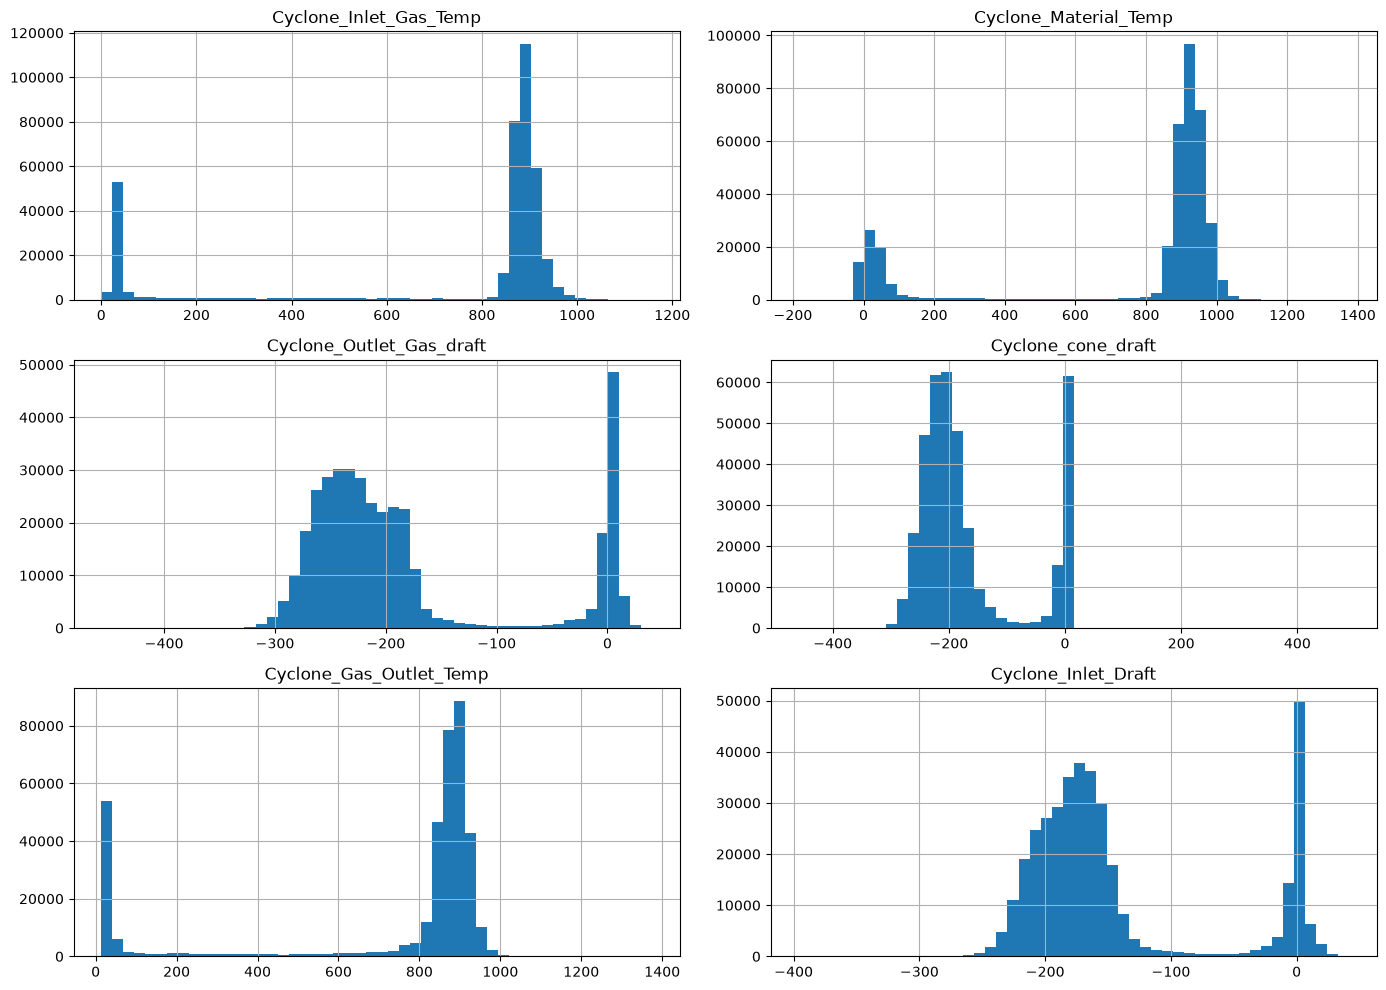

In [29]:
import matplotlib.pyplot as plt

sensor_numeric.hist(
    bins=50,
    figsize=(14, 10)
)

plt.tight_layout()
plt.show()

In [30]:
for col in [
    "Cyclone_Outlet_Gas_draft",
    "Cyclone_cone_draft",
    "Cyclone_Inlet_Draft"
]:
    print(f"\n{col}")
    print("Absolute value <= 10:", (sensor_numeric[col].abs() <= 10).sum())


Cyclone_Outlet_Gas_draft
Absolute value <= 10: 66276

Cyclone_cone_draft
Absolute value <= 10: 70336

Cyclone_Inlet_Draft
Absolute value <= 10: 66297


In [31]:
material_low = sensor_numeric.loc[
    sensor_numeric["Cyclone_Material_Temp"] <= 10,
    "Cyclone_Material_Temp"
]

print(material_low.describe())
print("\nMost common values:")
print(material_low.value_counts().head(20))

count    14382.000000
mean        -0.896092
std         12.513207
min       -185.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          9.860000
Name: Cyclone_Material_Temp, dtype: float64

Most common values:
Cyclone_Material_Temp
 0.00      14226
-185.00       49
 2.18         22
 1.10         13
 1.89         11
 2.49          6
 9.86          4
 0.99          4
 6.18          4
 0.97          3
-176.41        1
-119.01        1
-5.12          1
-55.41         1
 0.02          1
-54.05         1
-164.84        1
-46.70         1
-47.96         1
-22.55         1
Name: count, dtype: int64


In [32]:
material_zero = sensor_numeric[
    sensor_numeric["Cyclone_Material_Temp"] == 0
]

material_zero.describe().T

,count,mean,std,min,25%,50%,75%,max
Cyclone_Inlet_Gas_Temp,14226.0,61.437526,140.127124,22.79,29.50,31.225,33.48,1027.23
Cyclone_Material_Temp,14226.0,0.000000,0.000000,0.00,0.00,0.000,0.00,0.00
Cyclone_Outlet_Gas_draft,14226.0,-2.692649,34.781884,-290.78,1.45,2.145,4.80,38.11
Cyclone_cone_draft,14226.0,-6.108872,31.890359,-281.74,-0.75,-0.440,-0.10,15.07
Cyclone_Gas_Outlet_Temp,14226.0,60.921285,137.233111,25.69,29.95,31.500,33.33,1024.49
Cyclone_Inlet_Draft,14226.0,-6.061712,26.822493,-231.87,-2.02,-1.650,-1.32,32.78


In [33]:
zero_material_mask = (
    pd.to_numeric(df["Cyclone_Material_Temp"], errors="coerce") == 0
)

for col in sensor_cols:
    status_values = df.loc[zero_material_mask, col]

    non_numeric = pd.to_numeric(status_values, errors="coerce").isna()

    if non_numeric.any():
        print(f"\n{col}")
        print(status_values[non_numeric].value_counts())

In [34]:
correlation_matrix = sensor_numeric.corr()

correlation_matrix.round(2)

,Cyclone_Inlet_Gas_Temp,Cyclone_Material_Temp,Cyclone_Outlet_Gas_draft,Cyclone_cone_draft,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Draft
Cyclone_Inlet_Gas_Temp,1.00,0.96,-0.90,-0.90,0.99,-0.90
Cyclone_Material_Temp,0.96,1.00,-0.88,-0.88,0.96,-0.88
Cyclone_Outlet_Gas_draft,-0.90,-0.88,1.00,0.97,-0.90,1.00
Cyclone_cone_draft,-0.90,-0.88,0.97,1.00,-0.89,0.97
Cyclone_Gas_Outlet_Temp,0.99,0.96,-0.90,-0.89,1.00,-0.90
Cyclone_Inlet_Draft,-0.90,-0.88,1.00,0.97,-0.90,1.00


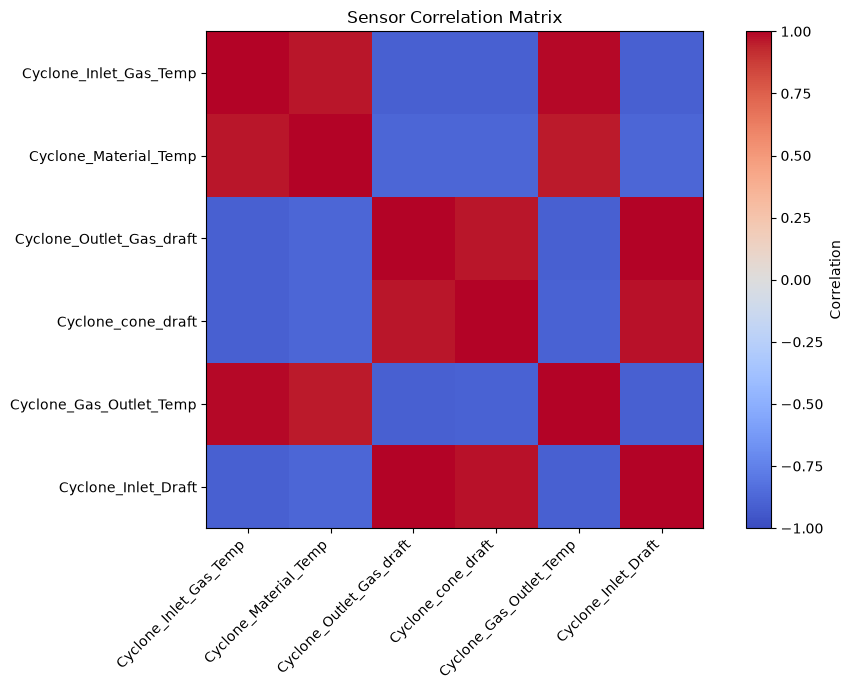

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.colorbar(label="Correlation")
plt.title("Sensor Correlation Matrix")
plt.tight_layout()
plt.show()

In [36]:
time_sensor_df = sensor_numeric.copy()
time_sensor_df["time_dt"] = df["time_dt"].values

daily_sensor = (
    time_sensor_df
    .set_index("time_dt")
    .resample("D")
    .median()
)

daily_sensor.shape

(1315, 6)

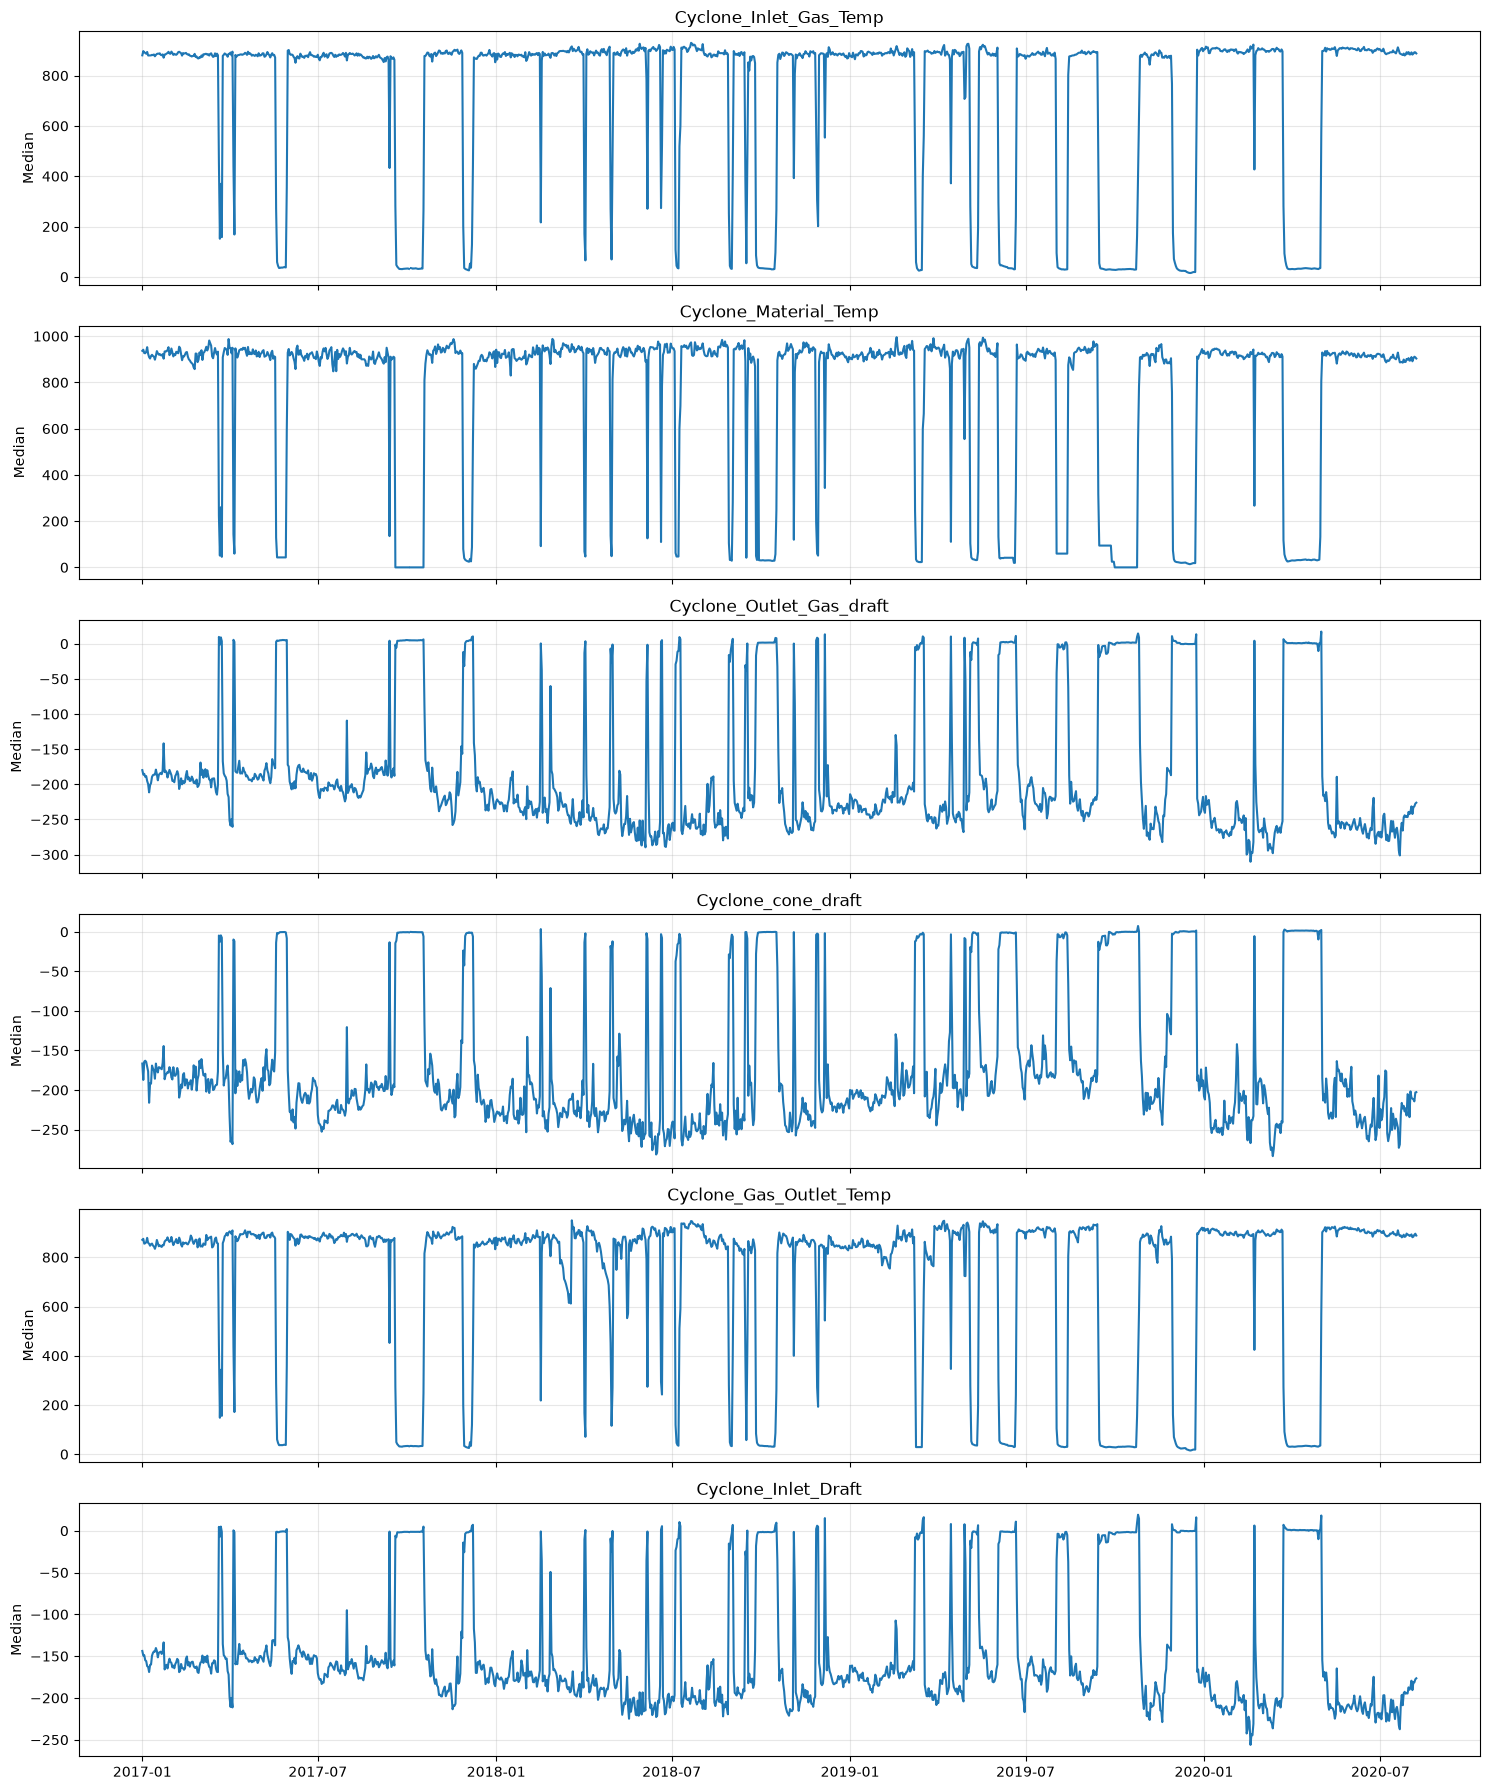

In [37]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    6, 1,
    figsize=(15, 18),
    sharex=True
)

for ax, col in zip(axes, sensor_numeric.columns):
    ax.plot(daily_sensor.index, daily_sensor[col])
    ax.set_title(col)
    ax.set_ylabel("Median")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Daily median trends: Daily median values are used for visualization to understand long-term process behavior while reducing the influence of individual extreme readings. The original 5-minute observations are retained for subsequent abnormal-period detection

In [38]:
hourly_sensor = (
    time_sensor_df
    .set_index("time_dt")
    .resample("h")
    .median()
)

print("Hourly data shape:", hourly_sensor.shape)

Hourly data shape: (31549, 6)


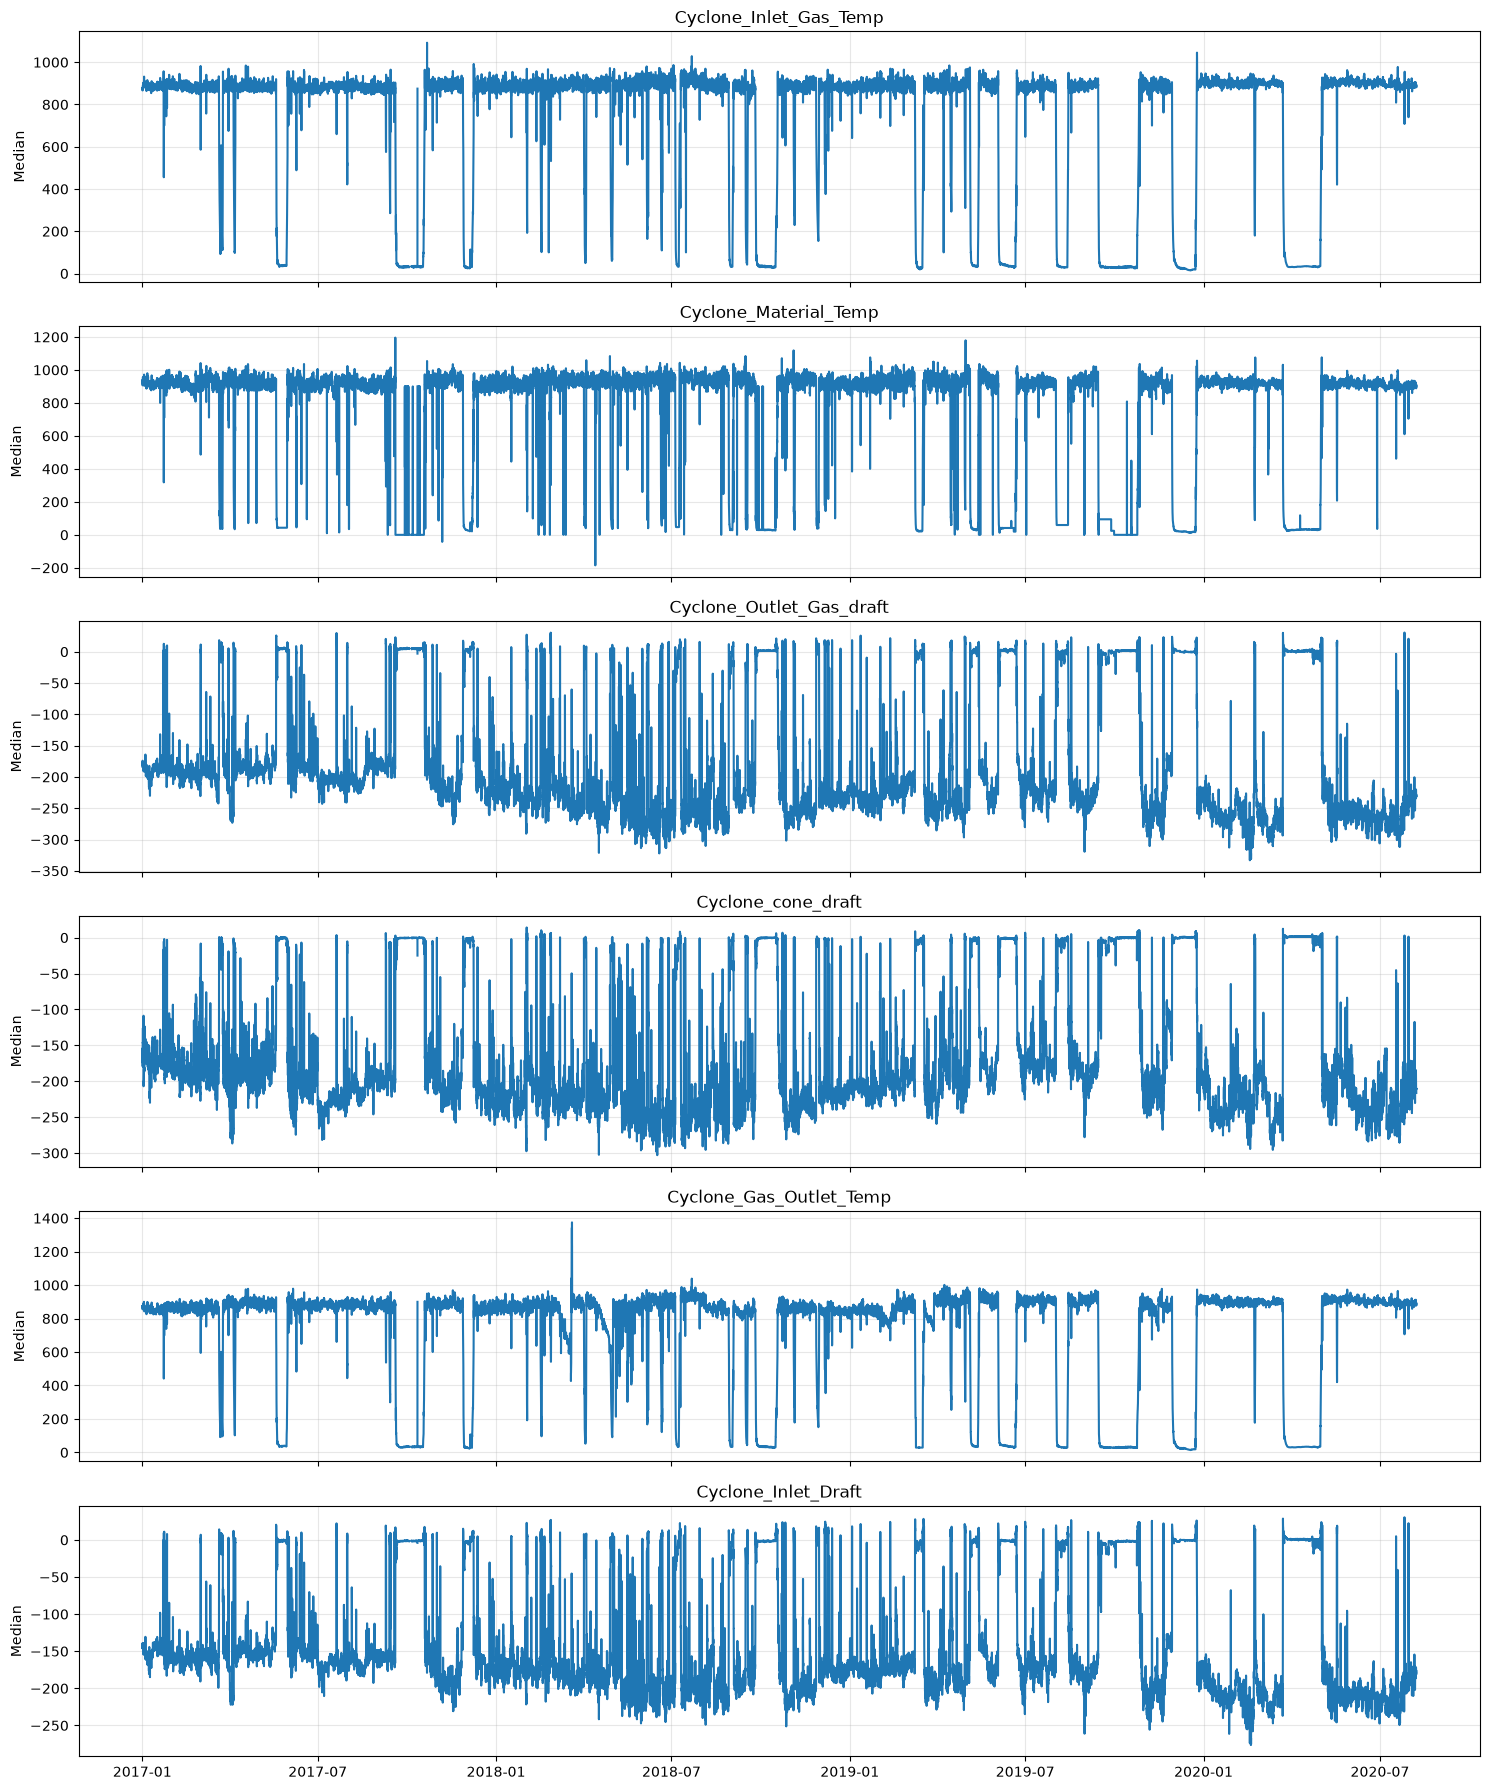

In [39]:
fig, axes = plt.subplots(
    6, 1,
    figsize=(15, 18),
    sharex=True
)

for ax, col in zip(axes, sensor_numeric.columns):
    ax.plot(hourly_sensor.index, hourly_sensor[col])
    ax.set_title(col)
    ax.set_ylabel("Median")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# Make sure time is datetime
df["time_dt"] = pd.to_datetime(df["time_dt"])

# Convert sensor columns to numeric
sensor_cols = [
    "Cyclone_Inlet_Gas_Temp",
    "Cyclone_Material_Temp",
    "Cyclone_Outlet_Gas_draft",
    "Cyclone_cone_draft",
    "Cyclone_Gas_Outlet_Temp",
    "Cyclone_Inlet_Draft"
]

for col in sensor_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Set time as index
plot_df = df.set_index("time_dt")

# Monthly median
monthly = plot_df[sensor_cols].resample("ME").median()

temperature plot

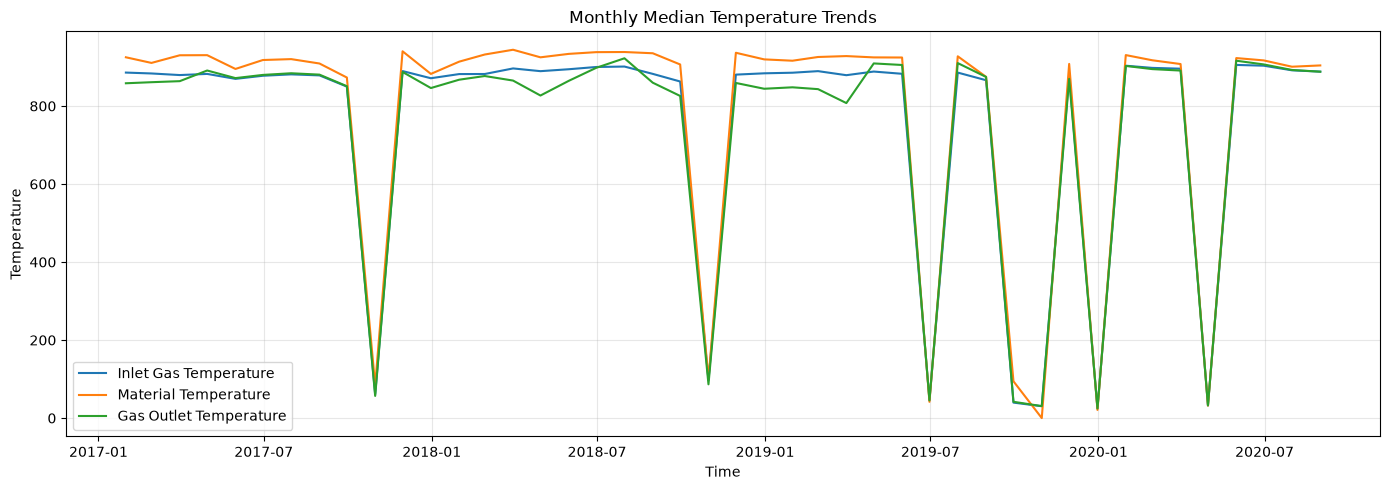

In [43]:
plt.figure(figsize=(14, 5))

plt.plot(monthly.index, monthly["Cyclone_Inlet_Gas_Temp"],
         label="Inlet Gas Temperature")

plt.plot(monthly.index, monthly["Cyclone_Material_Temp"],
         label="Material Temperature")

plt.plot(monthly.index, monthly["Cyclone_Gas_Outlet_Temp"],
         label="Gas Outlet Temperature")

plt.title("Monthly Median Temperature Trends")
plt.xlabel("Time")
plt.ylabel("Temperature")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

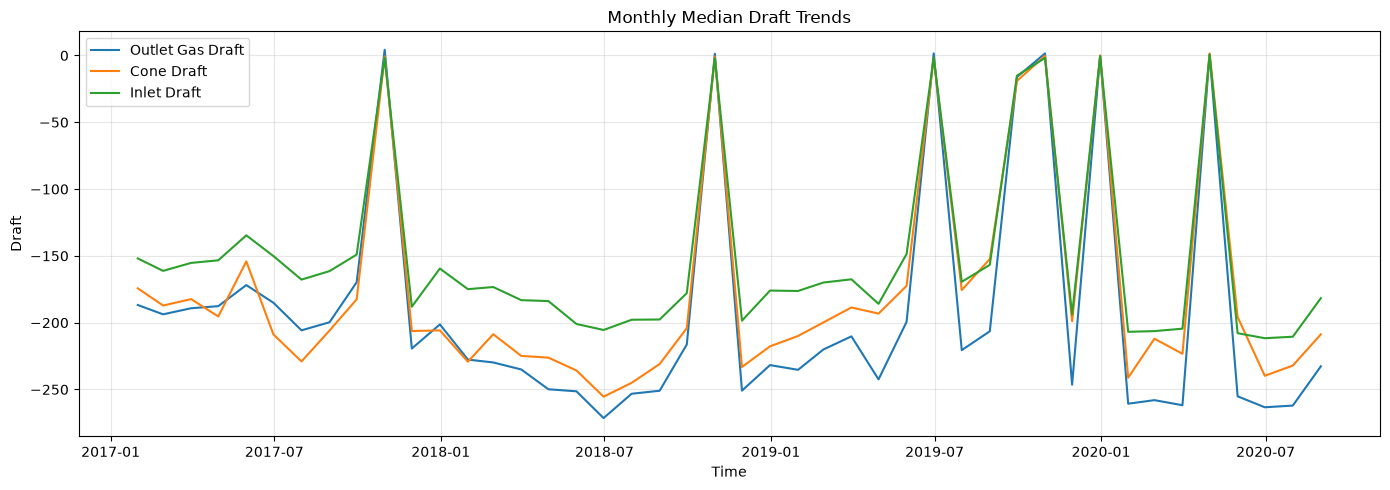

In [44]:
plt.figure(figsize=(14, 5))

plt.plot(monthly.index, monthly["Cyclone_Outlet_Gas_draft"],
         label="Outlet Gas Draft")

plt.plot(monthly.index, monthly["Cyclone_cone_draft"],
         label="Cone Draft")

plt.plot(monthly.index, monthly["Cyclone_Inlet_Draft"],
         label="Inlet Draft")

plt.title("Monthly Median Draft Trends")
plt.xlabel("Time")
plt.ylabel("Draft")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print("Rows with at least one missing sensor:")
print(sensor_numeric.isna().any(axis=1).sum())

print("Rows with all sensors available:")
print(sensor_numeric.notna().all(axis=1).sum())

Rows with at least one missing sensor:
1595
Rows with all sensors available:
376124


In [ ]:
status_values = [
    "Not Connect",
    "I/O Timeout",
    "Configure",
    "Scan Timeout",
    "Comm Fail",
    "Unit Down"
]

for status in status_values:
    mask = df[sensor_cols].isin([status]).any(axis=1)
    
    print(f"\n{status}")
    print("Total rows:", mask.sum())
    
    if mask.sum() > 0:
        print("First occurrence:", df.loc[mask, "time_dt"].min())
        print("Last occurrence:", df.loc[mask, "time_dt"].max())


Not Connect
Total rows: 723
First occurrence: 2017-10-03 11:20:00
Last occurrence: 2019-06-02 17:35:00

I/O Timeout
Total rows: 470
First occurrence: 2017-01-09 13:55:00
Last occurrence: 2020-01-29 21:15:00

Configure
Total rows: 108
First occurrence: 2017-10-06 04:35:00
Last occurrence: 2019-10-18 12:30:00

Scan Timeout
Total rows: 17
First occurrence: 2017-10-06 04:30:00
Last occurrence: 2019-03-14 16:10:00

Comm Fail
Total rows: 2
First occurrence: 2019-10-16 19:30:00
Last occurrence: 2019-10-16 19:35:00

Unit Down
Total rows: 275
First occurrence: 2017-01-16 20:45:00
Last occurrence: 2020-08-04 20:45:00


In [ ]:
status_mask = df[sensor_cols].isin(status_values)

status_summary = pd.DataFrame({
    "time": df["time_dt"],
    "status_sensor_count": status_mask.sum(axis=1)
})

print(status_summary["status_sensor_count"].value_counts().sort_index())

status_sensor_count
0    376124
1       275
6      1320
Name: count, dtype: int64


In [ ]:
multi_status = status_summary[
    status_summary["status_sensor_count"] >= 2
]

print("Timestamps with 2+ sensors having status:",
      len(multi_status))

print(multi_status.head(20))

Timestamps with 2+ sensors having status: 1320
                    time  status_sensor_count
2471 2017-01-09 13:55:00                    6
2472 2017-01-09 14:00:00                    6
2473 2017-01-09 14:05:00                    6
2474 2017-01-09 14:10:00                    6
2475 2017-01-09 14:15:00                    6
2476 2017-01-09 14:20:00                    6
2477 2017-01-09 14:25:00                    6
2478 2017-01-09 14:30:00                    6
2479 2017-01-09 14:35:00                    6
2480 2017-01-09 14:40:00                    6
2481 2017-01-09 14:45:00                    6
2482 2017-01-09 14:50:00                    6
2483 2017-01-09 14:55:00                    6
2484 2017-01-09 15:00:00                    6
2485 2017-01-09 15:05:00                    6
2486 2017-01-09 15:10:00                    6
2487 2017-01-09 15:15:00                    6
2488 2017-01-09 15:20:00                    6
2489 2017-01-09 15:25:00                    6
2490 2017-01-09 15:30:00         

In [ ]:
multi_status_details = df.loc[
    status_summary["status_sensor_count"] == 6,
    ["time"] + list(sensor_cols)
]

print(multi_status_details.head(20))

                  time Cyclone_Inlet_Gas_Temp Cyclone_Material_Temp  \
2471  01-09-2017 13:55            I/O Timeout           I/O Timeout   
2472  01-09-2017 14:00            I/O Timeout           I/O Timeout   
2473  01-09-2017 14:05            I/O Timeout           I/O Timeout   
2474  01-09-2017 14:10            I/O Timeout           I/O Timeout   
2475  01-09-2017 14:15            I/O Timeout           I/O Timeout   
2476  01-09-2017 14:20            I/O Timeout           I/O Timeout   
2477  01-09-2017 14:25            I/O Timeout           I/O Timeout   
2478  01-09-2017 14:30            I/O Timeout           I/O Timeout   
2479  01-09-2017 14:35            I/O Timeout           I/O Timeout   
2480  01-09-2017 14:40            I/O Timeout           I/O Timeout   
2481  01-09-2017 14:45            I/O Timeout           I/O Timeout   
2482  01-09-2017 14:50            I/O Timeout           I/O Timeout   
2483  01-09-2017 14:55            I/O Timeout           I/O Timeout   
2484  

In [ ]:
multi_status_details = df.loc[
    status_summary["status_sensor_count"] == 6,
    list(sensor_cols)
]

print(
    multi_status_details.apply(
        lambda row: tuple(row),
        axis=1
    ).value_counts()
)

(Not Connect, Not Connect, Not Connect, Not Connect, Not Connect, Not Connect)          723
(I/O Timeout, I/O Timeout, I/O Timeout, I/O Timeout, I/O Timeout, I/O Timeout)          470
(Configure, Configure, Configure, Configure, Configure, Configure)                      108
(Scan Timeout, Scan Timeout, Scan Timeout, Scan Timeout, Scan Timeout, Scan Timeout)     17
(Comm Fail, Comm Fail, Comm Fail, Comm Fail, Comm Fail, Comm Fail)                        2
Name: count, dtype: int64


In [ ]:
single_status_details = df.loc[
    status_summary["status_sensor_count"] == 1,
    ["time"] + list(sensor_cols)
]

print(single_status_details.head(20))

                   time Cyclone_Inlet_Gas_Temp Cyclone_Material_Temp  \
4569    1/16/2017 20:45                 897.54             Unit Down   
7303     1/26/2017 8:35                 901.66             Unit Down   
17182  03-01-2017 15:50                 872.21             Unit Down   
20997   3/14/2017 21:45                 889.82             Unit Down   
23926    3/25/2017 1:50                 486.91             Unit Down   
25594   3/30/2017 20:50                    875                   907   
26375  04-02-2017 13:55                 879.44             Unit Down   
27109  04-05-2017 03:05                 713.06             Unit Down   
28361  04-09-2017 11:25                 874.41             Unit Down   
28362  04-09-2017 11:30                 906.45             Unit Down   
29217  04-12-2017 10:45                 895.56             Unit Down   
29610   4/13/2017 19:30                 881.58             Unit Down   
33879   4/28/2017 15:15                    891             Unit 